# Quiz 9

k-means with 3 clusters and a 3-component Gaussian mixture on a 2D dataset with known labels (quiz9-data.csv, columns X1, X2, Y): scatter plots, the mixture's means, covariances and log-likelihood, and its density contours.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv("./quiz9-data.csv")
target = data.loc[:, "Y"]
data = data.drop(["Y"], axis=1)

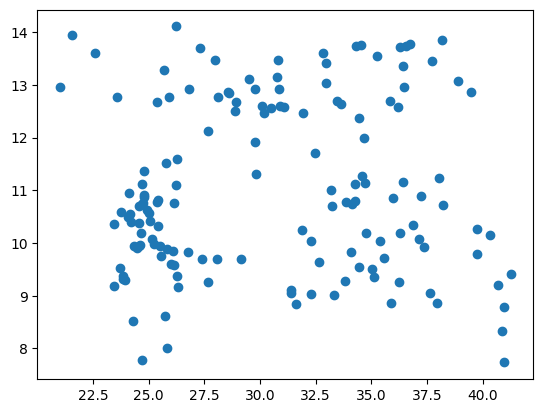

In [2]:
plt.scatter(data.X1, data.X2)
plt.show()

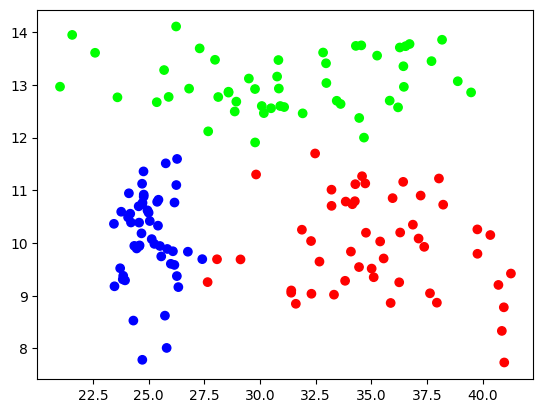

In [3]:
plt.scatter(data.X1, data.X2, c=target, cmap="brg")
plt.show()

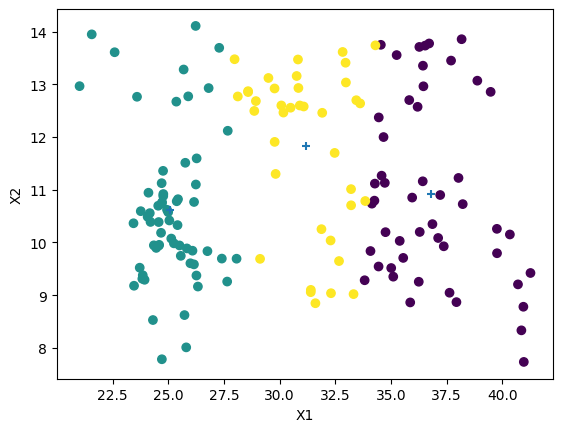

In [4]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=0).fit(data)
plt.scatter(data.X1, data.X2, c=kmeans.labels_)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="+")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

In [5]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(random_state=0, n_components=3, tol=0.0001).fit(data)
print(gm.means_)
print(gm.covariances_)
print(np.sum(gm.score_samples(data)))

[[31.15292435 13.05143606]
 [25.07113864 10.08807088]
 [35.21841046 10.01058474]]
[[[20.93211257  0.20499481]
  [ 0.20499481  0.27298612]]

 [[ 0.9519279  -0.04428129]
  [-0.04428129  0.68706322]]

 [[11.00885197 -0.80697254]
  [-0.80697254  0.90172765]]]
-669.5670314063259


In [6]:
x = np.linspace(np.min(data.loc[:, "X1"]), np.max(data.loc[:, "X1"]))
y = np.linspace(np.min(data.loc[:, "X2"]), np.max(data.loc[:, "X2"]))
X, Y = np.meshgrid(x, y)
XX = np.array([X.ravel(), Y.ravel()]).T
Z = -gm.score_samples(XX)
Z = Z.reshape(X.shape)

.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(


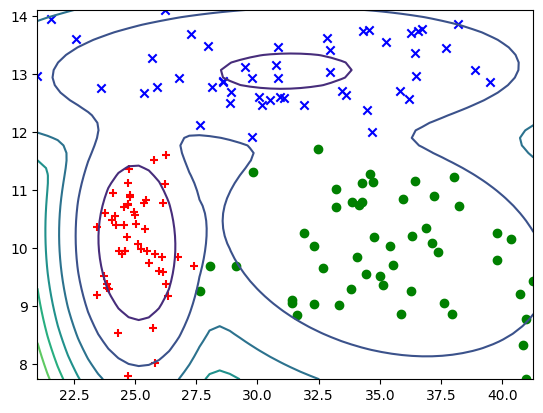

In [7]:
plt.contour(X, Y, Z)
plt.scatter(data[(target == 1)].X1, data[(target == 1)].X2, c="red", marker="+")
plt.scatter(data[(target == 2)].X1, data[(target == 2)].X2, c="green", marker="o")
plt.scatter(data[(target == 3)].X1, data[(target == 3)].X2, c="blue", marker="x")
plt.show()